# Example 3: Two-Dimensional Matrix Approach

For Example 3, only the matrix approach is used.

With $$\alpha=1$$, the model is

$$
u_t
=
c_d\left(u_{xx}+u_{yy}\right)
+
c_su(1-u)(u-a),
\qquad
-1\leq x,y\leq1.
$$

The initial condition is

$$
u(x,y,0)
=
(x-1)(x+1)(y-1)(y+1)
=
(x^2-1)(y^2-1).
$$

The boundary conditions are zero Dirichlet conditions:

$$
u(-1,y,t)=u(1,y,t)=0,
$$

$$
u(x,-1,t)=u(x,1,t)=0.
$$

The working parameters used here are

$$
c_d=1,\qquad c_s=50,\qquad a=0.5.
$$

The method is

$$
\boxed{
\text{Quasilinearization}
+
\text{2D Chebyshev collocation}
+
\text{Crank--Nicolson}
}
$$


## 1. Two-Dimensional Chebyshev Discretization

In one dimension,

$$
u_{xx}\approx D^{(2)}u.
$$

In two dimensions, the Laplacian is

$$
u_{xx}+u_{yy}.
$$

After keeping only the interior Chebyshev points, the 2D Laplacian can
be written as a Kronecker sum:

$$
\boxed{
L
=
D^{(2)}_I\otimes I
+
I\otimes D^{(2)}_I
}
$$

where $$(D^{(2)}_I)$$ is the interior part of the second-derivative
Chebyshev matrix.

Because all four boundary values are zero, there is no extra boundary
forcing term.


## 2. Crank--Nicolson and Quasilinearization

Let $$(v)$$ contain all interior values of the 2D solution.

The semi-discrete system is

$$
v_t=c_dLv+F(v),
$$

with
$$
F(v)=c_sv(1-v)(v-a).
$$

Crank--Nicolson gives

$$
\frac{v^{n+1}-v^n}{\Delta t}
=
\frac{c_d}{2}L(v^{n+1}+v^n)
+
\frac12
\left[
F(v^{n+1})+F(v^n)
\right].
$$

The nonlinear term is linearized using

$$
F(v_{r+1}^{n+1})
\approx
F(v_r^{n+1})
+
F'(v_r^{n+1})
\left(
v_{r+1}^{n+1}-v_r^{n+1}
\right).
$$

Define

$$
A_r=F'(v_r^{n+1}),
$$

and

$$
B_r
=
F(v_r^{n+1})
-
F'(v_r^{n+1})v_r^{n+1}.
$$

The linear system solved at each iteration is

$$
\boxed{
\left[
I-\frac{\Delta t}{2}c_dL
-\frac{\Delta t}{2}\operatorname{diag}(A_r)
\right]
v_{r+1}^{n+1}
=
\left[
I+\frac{\Delta t}{2}c_dL
\right]v^n
+
\frac{\Delta t}{2}
\left[
F(v^n)+B_r
\right].
}
$$


## 3. Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import RectBivariateSpline
from scipy.sparse import csr_matrix, diags, eye, kron
from scipy.sparse.linalg import spsolve


## 4. Chebyshev Differentiation Matrix


In [2]:
def cheb(N):

    if N == 0:
        return np.array([[0.0]]), np.array([1.0])

    x = np.cos(
        np.pi * np.arange(N + 1) / N
    )

    c = np.ones(N + 1)
    c[0] = 2.0
    c[-1] = 2.0

    c *= (-1.0) ** np.arange(N + 1)

    X = np.tile(
        x.reshape(N + 1, 1),
        (1, N + 1)
    )

    dX = X - X.T

    D = (
        (
            c.reshape(N + 1, 1)
            / c.reshape(1, N + 1)
        )
        /
        (
            dX + np.eye(N + 1)
        )
    )

    D = D - np.diag(
        np.sum(D, axis=1)
    )

    return D, x


### Quick Check


In [3]:
D_test, x_test = cheb(10)

print(
    "D @ x error =",
    np.max(
        np.abs(
            D_test @ x_test - 1
        )
    )
)

print(
    "D2 @ x^2 error =",
    np.max(
        np.abs(
            (D_test @ D_test) @ (x_test**2) - 2
        )
    )
)


D @ x error = 1.7763568394002505e-15
D2 @ x^2 error = 1.1368683772161603e-13


## 5. Reaction Term


In [4]:
def reaction(u, cs, a):

    return (
        cs
        * u
        * (1-u)
        * (u-a)
    )


def reaction_derivative(u, cs, a):

    return (
        cs
        * (
            -3*u**2
            + 2*(1+a)*u
            - a
        )
    )


## 6. Two-Dimensional Matrix Solver


In [5]:
def solve_example3_matrix(
    N=20,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    dt=0.001,
    tol=1e-10,
    max_iter=30
):

    # --------------------------------------------------
    # 1D Chebyshev grid
    # --------------------------------------------------
    D, x = cheb(N)
    D2 = D @ D

    # Interior points only
    x_int = x[1:-1]

    m = N - 1

    D2_int = csr_matrix(
        D2[1:-1, 1:-1]
    )

    I1 = eye(
        m,
        format="csr"
    )

    # --------------------------------------------------
    # 2D Laplacian:
    # Dxx + Dyy
    # --------------------------------------------------
    L = (
        kron(D2_int, I1, format="csr")
        +
        kron(I1, D2_int, format="csr")
    )

    I2 = eye(
        m*m,
        format="csr"
    )

    # --------------------------------------------------
    # Initial condition on interior grid
    # --------------------------------------------------
    X_int, Y_int = np.meshgrid(
        x_int,
        x_int,
        indexing="ij"
    )

    U_int = (
        (X_int**2 - 1.0)
        *
        (Y_int**2 - 1.0)
    )

    v = U_int.ravel()

    # --------------------------------------------------
    # Time setup
    # --------------------------------------------------
    Nt = int(
        np.ceil(
            t_final / dt
        )
    )

    dt = t_final / Nt

    A_diffusion = (
        I2
        -
        0.5 * dt * cd * L
    )

    B_diffusion = (
        I2
        +
        0.5 * dt * cd * L
    )

    # --------------------------------------------------
    # Midpoint history
    # For even N, x=0 is exactly a Chebyshev point.
    # --------------------------------------------------
    mid_full = np.argmin(
        np.abs(x)
    )

    time_values = [0.0]

    U_full_initial = np.zeros(
        (N + 1, N + 1)
    )

    U_full_initial[1:-1, 1:-1] = (
        U_int
    )

    midpoint_values = [
        U_full_initial[
            mid_full,
            mid_full
        ]
    ]

    maximum_iterations_used = 0

    # ==================================================
    # TIME LOOP
    # ==================================================
    for n in range(Nt):

        v_old = v.copy()
        v_iter = v_old.copy()

        converged = False

        for r in range(max_iter):

            F_iter = reaction(
                v_iter,
                cs,
                a
            )

            Fprime_iter = (
                reaction_derivative(
                    v_iter,
                    cs,
                    a
                )
            )

            B_r = (
                F_iter
                -
                Fprime_iter * v_iter
            )

            A = (
                A_diffusion
                -
                0.5 * dt
                * diags(
                    Fprime_iter,
                    format="csr"
                )
            )

            rhs = (
                B_diffusion @ v_old
                +
                0.5 * dt
                * (
                    reaction(
                        v_old,
                        cs,
                        a
                    )
                    +
                    B_r
                )
            )

            v_next = spsolve(
                A,
                rhs
            )

            iteration_error = np.max(
                np.abs(
                    v_next - v_iter
                )
            )

            v_iter = v_next

            if iteration_error < tol:
                converged = True
                break

        if not converged:
            raise RuntimeError(
                f"Quasilinearization did not converge at time step {n+1}."
            )

        maximum_iterations_used = max(
            maximum_iterations_used,
            r + 1
        )

        v = v_iter

        # Reconstruct full solution with zero boundary values
        U_full = np.zeros(
            (N + 1, N + 1)
        )

        U_full[1:-1, 1:-1] = (
            v.reshape(
                (m, m)
            )
        )

        time_values.append(
            (n + 1) * dt
        )

        midpoint_values.append(
            U_full[
                mid_full,
                mid_full
            ]
        )

    return (
        x,
        U_full,
        np.array(time_values),
        np.array(midpoint_values),
        dt,
        maximum_iterations_used
    )


## 7. Main Solution

For the maximum-error comparison we need the solution at

\[
t=0.5.
\]

For the midpoint graph, Example 3 follows

\[
u(0,0,t)
\]

over a longer interval, so a separate main run to \(t=1\) is used below.


In [7]:
(
    x_main,
    U_main,
    t_main,
    midpoint_main,
    dt_used,
    max_iterations
) = solve_example3_matrix(
    N=20,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=1.0,
    dt=0.001
)

print("dt =", dt_used)
print("Starting midpoint =", midpoint_main[0])
print(
    "Midpoint at t = 0.5 =",
    midpoint_main[
        np.argmin(
            np.abs(t_main - 0.5)
        )
    ]
)
print(
    "Midpoint at t = 1.0 =",
    midpoint_main[-1]
)
print(
    "Maximum nonlinear iterations used =",
    max_iterations
)
print(
    "Minimum final value =",
    np.min(U_main)
)
print(
    "Maximum final value =",
    np.max(U_main)
)
print(
    "Contains NaN =",
    np.isnan(U_main).any()
)
print(
    "Contains infinity =",
    np.isinf(U_main).any()
)


dt = 0.001
Starting midpoint = 1.0
Midpoint at t = 0.5 = 6.554877574415084e-05
Midpoint at t = 1.0 = 2.062004362247499e-11
Maximum nonlinear iterations used = 3
Minimum final value = 0.0
Maximum final value = 2.062004362247499e-11
Contains NaN = False
Contains infinity = False


## 8. Midpoint Graph u(0,0,t) 

For Example 3, the centre of the domain is

$$
(x,y)=(0,0).
$$

From the initial condition,

$$
u(0,0,0)=1.
$$


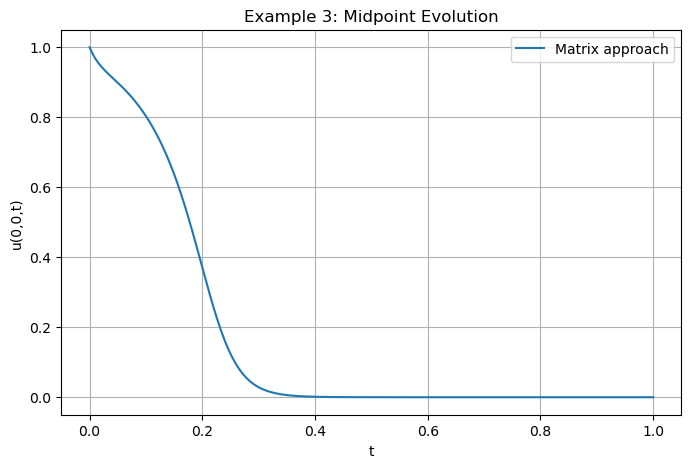

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    t_main,
    midpoint_main,
    label="Matrix approach"
)

plt.xlabel("t")
plt.ylabel("u(0,0,t)")
plt.title("Example 3: Midpoint Evolution")
plt.grid(True)
plt.legend()

plt.show()


## 9. Final Surface at \(t=1\)


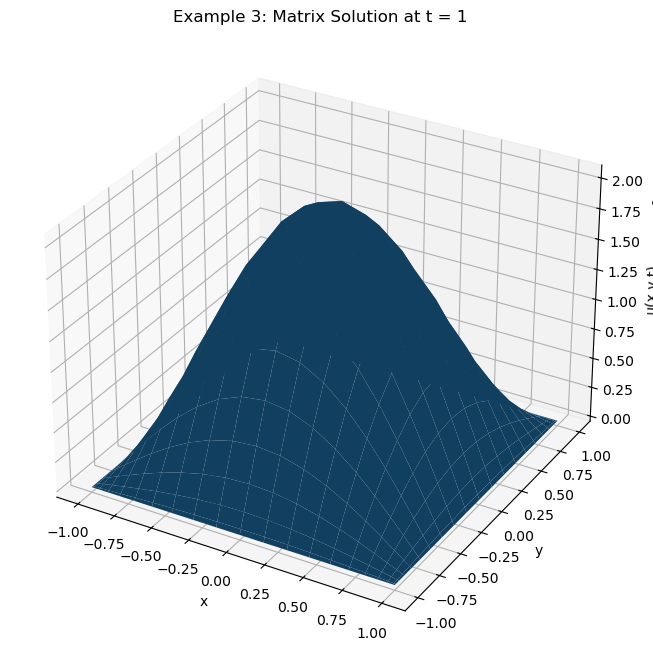

In [11]:
X, Y = np.meshgrid(
    x_main,
    x_main,
    indexing="ij"
)

fig = plt.figure(
    figsize=(8, 10)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.plot_surface(
    X,
    Y,
    U_main
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("u(x,y,t)")
ax.set_title(
    "Example 3: Matrix Solution at t = 1"
)

plt.show()


## 11. Load the Mathematica Reference


In [12]:
ndsolve_data = pd.read_csv(
    "example3_ndsolve_t05.csv"
)

x_ref = np.sort(
    ndsolve_data["x"].unique()
)

y_ref = np.sort(
    ndsolve_data["y"].unique()
)

U_ref_table = (
    ndsolve_data
    .pivot(
        index="x",
        columns="y",
        values="u"
    )
    .sort_index()
    .sort_index(axis=1)
)

U_ref = (
    U_ref_table
    .to_numpy(dtype=float)
)

ndsolve_interp = RectBivariateSpline(
    x_ref,
    y_ref,
    U_ref,
    kx=3,
    ky=3
)

print(
    "NDSolve 2D reference loaded successfully."
)

print(
    "Number of x points =",
    len(x_ref)
)

print(
    "Number of y points =",
    len(y_ref)
)

print(
    "x-range =",
    (x_ref[0], x_ref[-1])
)

print(
    "y-range =",
    (y_ref[0], y_ref[-1])
)

boundary_max = max(
    np.max(
        np.abs(
            U_ref[0, :]
        )
    ),
    np.max(
        np.abs(
            U_ref[-1, :]
        )
    ),
    np.max(
        np.abs(
            U_ref[:, 0]
        )
    ),
    np.max(
        np.abs(
            U_ref[:, -1]
        )
    )
)

print(
    "Maximum boundary value =",
    boundary_max
)


NDSolve 2D reference loaded successfully.
Number of x points = 401
Number of y points = 401
x-range = (np.float64(-1.0), np.float64(1.0))
y-range = (np.float64(-1.0), np.float64(1.0))
Maximum boundary value = 1.694065894508601e-21


## 12. Maximum Absolute Error

The paper uses

$$
N_x=N_y=N,
$$

with

$$
N=5,10,15,20,25,30.
$$

For each value of $$N$$,

$$
E_{\max}
=
\max_{i,j}
\left|
u_{\mathrm{matrix}}(x_i,y_j,0.5)
-
u_{\mathrm{NDSolve}}(x_i,y_j,0.5)
\right|.
$$


In [14]:
N_values = [
    5,
    10,
    15,
    20,
    25,
    30
]

matrix_errors = []

print(
    "N        Maximum absolute error vs NDSolve"
)

print(
    "------------------------------------------"
)

for N in N_values:

    (
        x_test,
        U_test,
        _,
        _,
        _,
        _
    ) = solve_example3_matrix(
        N=N,
        cd=1.0,
        cs=50.0,
        a=0.5,
        t_final=0.5,
        dt=0.001
    )

    # Create the 2D grid using Chebyshev points
    X_test, Y_test = np.meshgrid(
        x_test,
        x_test,
        indexing="ij"
    )

    # Evaluate NDSolve at the same points as the matrix solution
    U_nd_at_test = ndsolve_interp(
        X_test,
        Y_test,
        grid=False
    )

    max_error = np.max(
        np.abs(
            U_test
            -
            U_nd_at_test
        )
    )

    matrix_errors.append(
        max_error
    )

    print(
        f"{N:<8} {max_error:.10f}"
    )


N        Maximum absolute error vs NDSolve
------------------------------------------
5        0.0000300855
10       0.0000000853
15       0.0000001327
20       0.0000001392
25       0.0000001392
30       0.0000001342


## 13. Error Table


In [15]:
error_table = pd.DataFrame({
    "N": N_values,
    "Maximum absolute error": matrix_errors
})

display(
    error_table.style.format({
        "Maximum absolute error": "{:.10f}"
    })
)


,N,Maximum absolute error
0,5,0.0000300855
1,10,0.0000000853
2,15,0.0000001327
3,20,0.0000001392
4,25,0.0000001392
5,30,0.0000001342


## 14. Original Paper Values

The paper reports:

| \(N_x=N_y\) | Error vs `NDSolve` |
|---:|---:|
| 5  | 0.0000505810 |
| 10 | 0.0000647872 |
| 15 | 0.0000631025 |
| 20 | 0.0000647874 |
| 25 | 0.0000642415 |
| 30 | 0.0000647874 |

Once the present matrix errors are available, the two sets of results
can be plotted together and discussed.


## 15. Matrix Method vs Original Paper


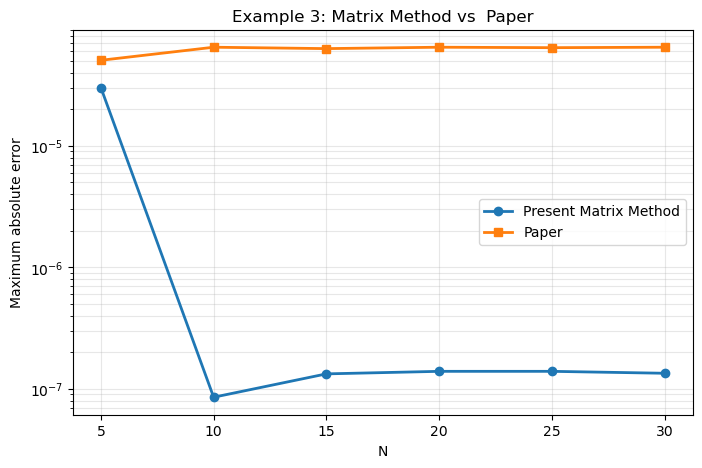

In [18]:
paper_errors = [
    0.0000505810,
    0.0000647872,
    0.0000631025,
    0.0000647874,
    0.0000642415,
    0.0000647874
]

plt.figure(figsize=(8, 5))

plt.semilogy(
    N_values,
    matrix_errors,
    marker="o",
    linewidth=2,
    label="Present Matrix Method"
)

plt.semilogy(
    N_values,
    paper_errors,
    marker="s",
    linewidth=2,
    label="Paper"
)

plt.xlabel("N")
plt.ylabel("Maximum absolute error")
plt.title(
    "Example 3: Matrix Method vs  Paper"
)

plt.xticks(N_values)

plt.grid(
    True,
    which="both",
    alpha=0.3
)

plt.legend()

plt.show()


## 16. Discussion

First look at how the present matrix error behaves as \(N\) increases.

Then compare that pattern with the original paper.

The midpoint graph

\[
u(0,0,t)
\]

should also be discussed separately because it shows the time behaviour
of the solution, while the error table measures the difference from
`NDSolve` at \(t=0.5\).
